In [2]:
import os
import numpy as np 
import pandas as pd
from tqdm import tqdm 
from muq import MuQ
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
from typing import Dict, List, Tuple, Optional
import json
import matplotlib.pyplot as plt
from collections import Counter

In [4]:
import sys
sys.path.append("/home/waarab/ia/free-gen-playlist")
from Viz.tsne_vis import load_embeddings

sys.path.append(os.path.abspath("../embeddings"))

## T-SNE visualization of MuQ embeddings

In [5]:
csv_path = "../embeddings/muq_embedding_jamendo_multiclass.csv"
data = pd.read_csv(csv_path)
genres = data['genre']  # 'genre' tags
instruments = data['instrument']  #  'instrument' tags
emotions = data['emotion']  #  'emotion' tags


filenames = data['filename']  #  the last column is 'filename'

data.drop(columns=['instrument', 'filename','genre','emotion'], inplace=True)
embeddings , genres , filenames = data.to_numpy(), genres.to_numpy(), filenames.to_numpy()
X_2d = TSNE(n_components=2, random_state=42).fit_transform(embeddings)
print("Loaded embeddings shape:", embeddings.shape)
print("t-SNE result shape:", X_2d.shape)


Loaded embeddings shape: (1104, 1024)
t-SNE result shape: (1104, 2)


### 1-Genres 

✅ t-SNE plot saved as tsne_muQ_raw_embeddings_jamendo_genres.png


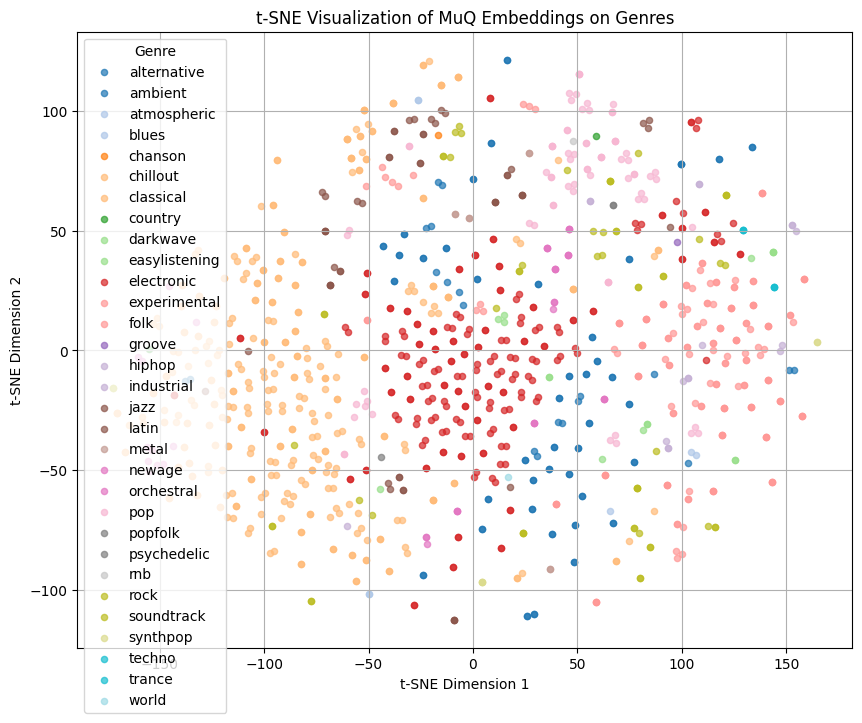

In [6]:
plt.figure(figsize=(10, 8))

# Obtenir la liste unique des genres
unique_genres = np.unique(genres)
n_classes = len(unique_genres)

cmap = plt.get_cmap("tab20")
colors = [cmap(i / n_classes) for i in range(n_classes)]
class_to_color = {cls: colors[i] for i, cls in enumerate(unique_genres)}
# Plot genre par genre
for genre in unique_genres:
    idx = genres == genre
    plt.scatter(X_2d[idx, 0], X_2d[idx, 1], label=genre, color=class_to_color[genre], alpha=0.7, s=20)
plt.title("t-SNE Visualization of MuQ Embeddings on Genres")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="Genre")
plt.grid(True)
# Sauvegarde du graphique
plt.savefig("../fig/tsne_muQ_raw_embeddings_jamendo_genres.png", dpi=300)
print("✅ t-SNE plot saved as tsne_muQ_raw_embeddings_jamendo_genres.png")

### 2- Instruments

✅ t-SNE plot saved as tsne_muQ_raw_embeddings_jamendo_instruments.png


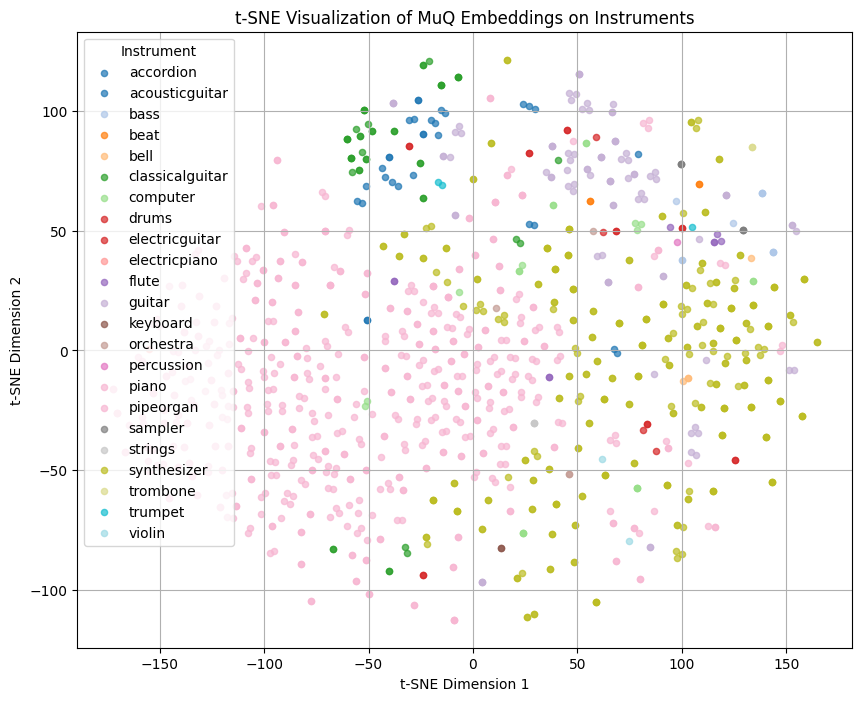

In [7]:
plt.figure(figsize=(10, 8))

# Obtenir la liste unique des instruments
unique_instruments = np.unique(instruments)
n_classes = len(unique_instruments)

cmap = plt.get_cmap("tab20")
colors = [cmap(i / n_classes) for i in range(n_classes)]
class_to_color = {cls: colors[i] for i, cls in enumerate(unique_instruments)}
# Plot instrument par instrument
for instrument in unique_instruments:
    idx = instruments == instrument
    plt.scatter(X_2d[idx, 0], X_2d[idx, 1], label=instrument, color=class_to_color[instrument], alpha=0.7, s=20)
plt.title("t-SNE Visualization of MuQ Embeddings on Instruments")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="Instrument")
plt.grid(True)
# Sauvegarde du graphique
plt.savefig("../fig/tsne_muQ_raw_embeddings_jamendo_instruments.png", dpi=300)
print("✅ t-SNE plot saved as tsne_muQ_raw_embeddings_jamendo_instruments.png")

### 3- Emotions

✅ t-SNE plot saved as tsne_muQ_raw_embeddings_jamendo_emotions.png


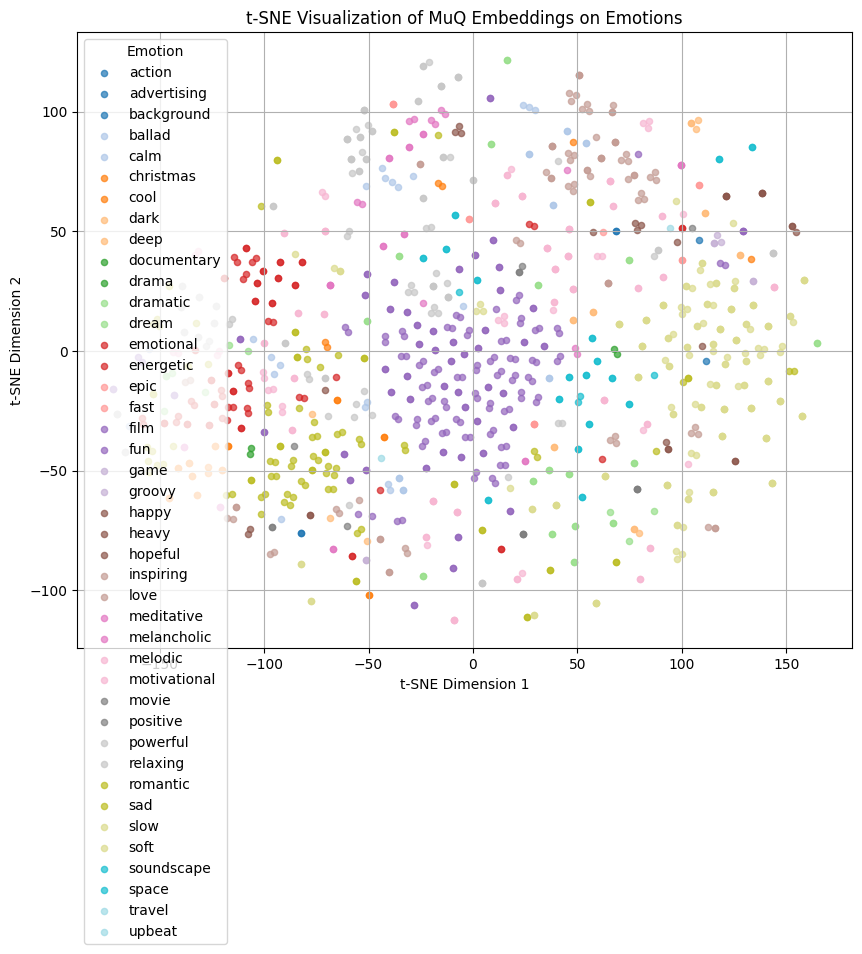

In [8]:
plt.figure(figsize=(10, 8))

# Obtenir la liste unique des emotions
unique_emotions = np.unique(emotions)
n_classes = len(unique_emotions)

cmap = plt.get_cmap("tab20")
colors = [cmap(i / n_classes) for i in range(n_classes)]
class_to_color = {cls: colors[i] for i, cls in enumerate(unique_emotions)}
# Plot emotion par emotion
for emotion in unique_emotions:
    idx = emotions == emotion
    plt.scatter(X_2d[idx, 0], X_2d[idx, 1], label=emotion, color=class_to_color[emotion], alpha=0.7, s=20)
plt.title("t-SNE Visualization of MuQ Embeddings on Emotions")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="Emotion")
plt.grid(True)
# Sauvegarde du graphique
plt.savefig("../fig/tsne_muQ_raw_embeddings_jamendo_emotions.png", dpi=300)
print("✅ t-SNE plot saved as tsne_muQ_raw_embeddings_jamendo_emotions.png")

## Count occurence for each tag

In [13]:
# Compter les occurrences
genre_counts = Counter(genres)
instrument_counts = Counter(instruments)
emotion_counts = Counter(emotions)

# Convertir en DataFrame pour lecture
df_genre = pd.DataFrame(genre_counts.items(), columns=['Genre', 'Count']).sort_values(by='Count', ascending=False)
df_instrument = pd.DataFrame(instrument_counts.items(), columns=['Instrument', 'Count']).sort_values(by='Count', ascending=False)
df_emotion = pd.DataFrame(emotion_counts.items(), columns=['Emotion', 'Count']).sort_values(by='Count', ascending=False)

### 1- Genres

In [14]:
df_genre.head()

,Genre,Count
0,classical,334
5,electronic,211
18,experimental,148
1,ambient,101
11,pop,75


### 2. Instruments

In [15]:
df_instrument.head()

,Instrument,Count
0,piano,557
2,synthesizer,287
4,guitar,90
5,classicalguitar,45
7,acousticguitar,28


### 3. Emotions

In [16]:
df_emotion.head()


,Emotion,Count
8,film,196
20,slow,155
0,relaxing,101
3,melodic,97
14,emotional,70


## Dataset distribution

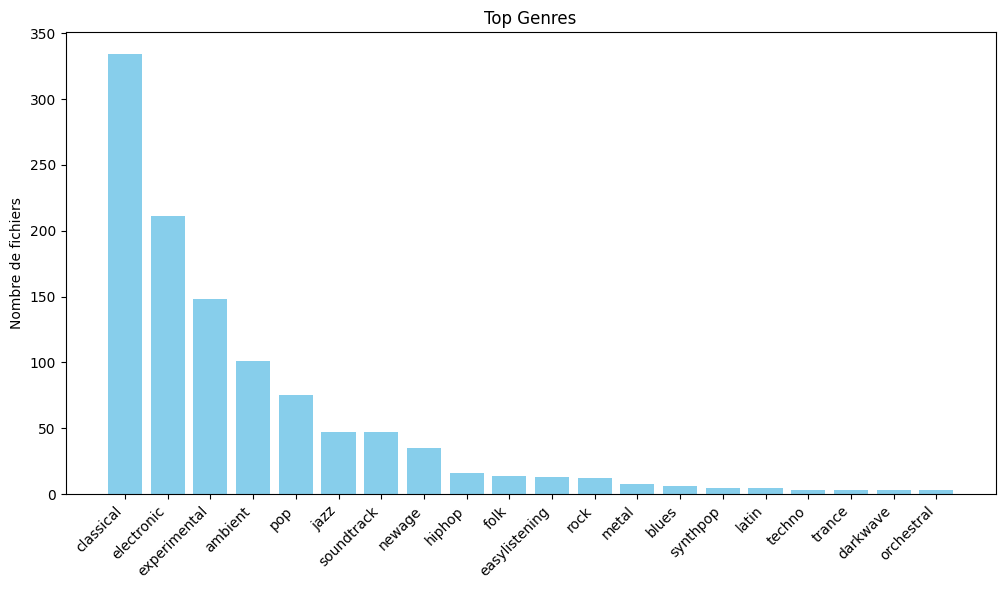

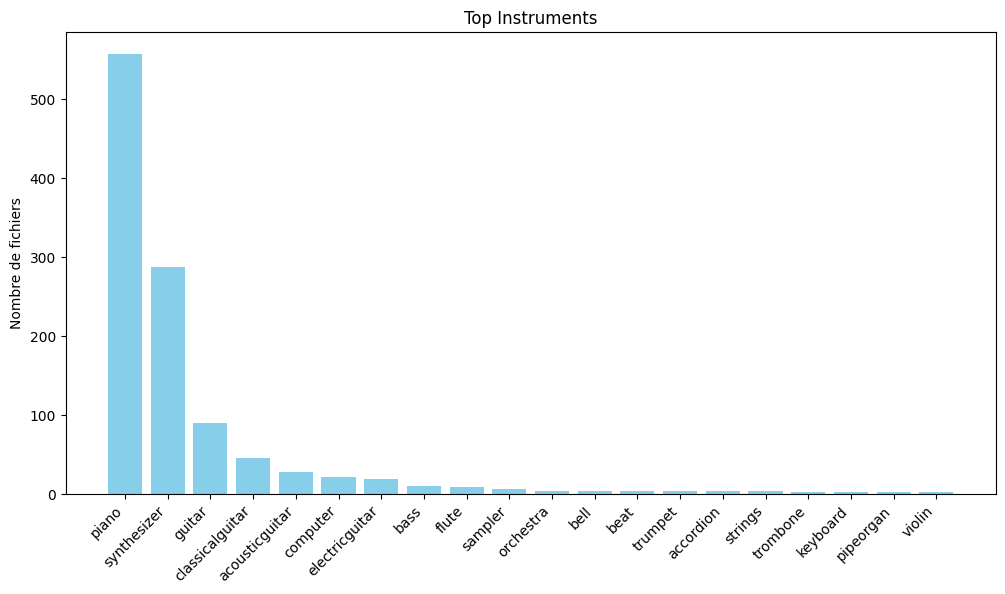

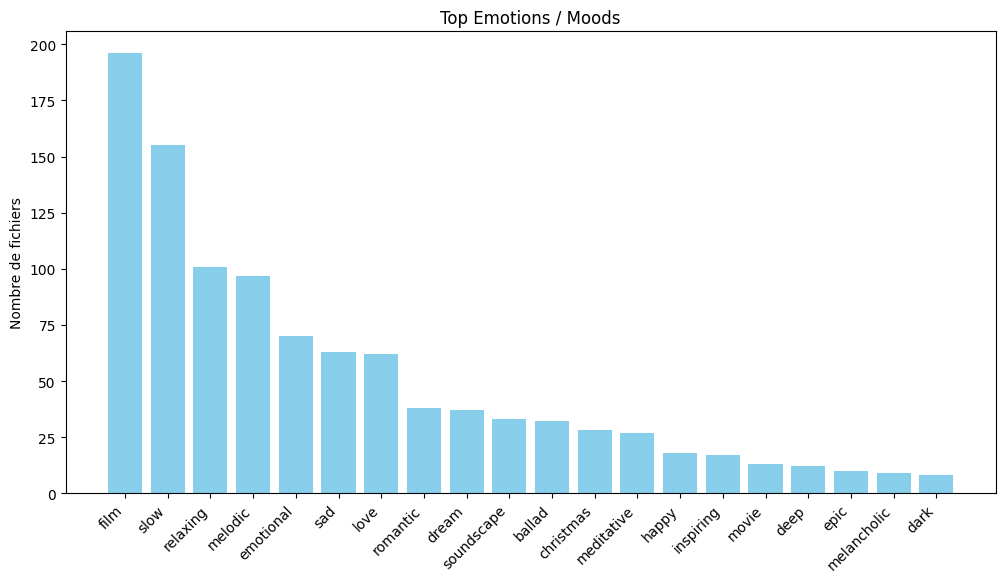

In [17]:
def plot_top_tags(df, tag_column, count_column, title, top_n=20):
    top_df = df.head(top_n)
    plt.figure(figsize=(12,6))
    plt.bar(top_df[tag_column], top_df[count_column], color='skyblue')
    plt.xticks(rotation=45, ha='right')
    plt.title(title)
    plt.ylabel("Nombre de fichiers")
    plt.show()

plot_top_tags(df_genre, 'Genre', 'Count', "Top Genres")
plot_top_tags(df_instrument, 'Instrument', 'Count', "Top Instruments")
plot_top_tags(df_emotion, 'Emotion', 'Count', "Top Emotions / Moods")


In [20]:
# Charger CSV
csv_path = "../embeddings/muq_embedding_jamendo_multiclass.csv"
data = pd.read_csv(csv_path)

# Définir un seuil maximum pour les classes
max_per_class = 50

# Fonction pour limiter chaque classe
def balance_class(df, column, max_count):
    balanced_list = []
    for cls, group in df.groupby(column):
        if len(group) > max_count:
            group = group.sample(max_count, random_state=42)  # prendre un sous-échantillon
        balanced_list.append(group)
    return pd.concat(balanced_list).reset_index(drop=True)

# Appliquer pour les genres, instruments et émotions
data_balanced = balance_class(data, 'genre', max_per_class)
data_balanced = balance_class(data_balanced, 'instrument', max_per_class)
data_balanced = balance_class(data_balanced, 'emotion', max_per_class)

print("Shape du dataset équilibré :", data_balanced.shape)


Shape du dataset équilibré : (258, 1028)
